In [2]:
# Imports and settings

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore")

DATA = "../data/diabetic_data.csv"   # <-- path to your file
SEED = 42

In [4]:
#Load and clean the data

In [5]:
df = pd.read_csv(DATA, na_values="?", low_memory=False)
print(f"Hospital stays in the file: {len(df):,}")

# Remove patients who died or went to hospice (they cannot be readmitted), and invalid gender
DEATH_OR_HOSPICE = {11, 13, 14, 19, 20, 21}
df = df[~df["discharge_disposition_id"].isin(DEATH_OR_HOSPICE)]
df = df[df["gender"].isin(["Male", "Female"])].reset_index(drop=True)

y = (df["readmitted"] == "<30").astype(int).to_numpy()   # 1 = readmitted within 30 days
groups = df["patient_nbr"].to_numpy()                    # patient ID

print(f"Hospital stays after cleaning: {len(df):,}")
print(f"Different patients: {len(np.unique(groups)):,}")
print(f"Readmitted within 30 days: {y.sum():,} stays ({y.mean():.1%})")

Hospital stays in the file: 101,766
Hospital stays after cleaning: 99,340
Different patients: 69,987
Readmitted within 30 days: 11,314 stays (11.4%)


In [6]:
#split into training and test

In [7]:
# The four pieces of information the score uses
X = pd.DataFrame({
    "length_of_stay": df["time_in_hospital"].astype(float),
    "emergency_admission": (df["admission_type_id"] == 1).astype(int),
    "number_of_diagnoses": df["number_diagnoses"].astype(float),
    "emergency_visits_last_year": df["number_emergency"].astype(float),
})

# Split by patient: 80% to build the model, 20% kept aside to test it
split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tr, te = next(split.split(X, y, groups))
Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y[tr], y[te]

print(f"Training stays: {len(tr):,} | Test stays: {len(te):,}")
print("Patients in both groups:", len(set(groups[tr]) & set(groups[te])), "(must be 0)")

Training stays: 79,567 | Test stays: 19,773
Patients in both groups: 0 (must be 0)


In [8]:
#The model, a clinical points score

In [9]:
# The model: a clinical points score in the style of the LACE index used in hospitals.
# The dataset has no Charlson comorbidity index, so the number of diagnoses stands in for it.
def score_parts(X):
    """Points for each of the four parts of the score."""
    los = X["length_of_stay"]
    return pd.DataFrame({
        "Length of stay": np.select([los >= 14, los >= 7, los >= 4], [7, 5, 4], default=los.clip(upper=3)),
        "Emergency admission": 3 * X["emergency_admission"],
        "Number of diagnoses": (X["number_of_diagnoses"] - 4).clip(lower=0, upper=5),
        "Emergency visits last year": X["emergency_visits_last_year"].clip(upper=4),
    }, index=X.index).astype(int)

points_table = pd.DataFrame({
    "Risk factor": ["Length of stay", "Emergency admission", "Number of diagnoses", "Emergency visits last year"],
    "How points are given": ["1 day = 1, 2 days = 2, 3 days = 3, 4-6 days = 4, 7-13 days = 5, 14+ days = 7",
                             "Yes = 3, No = 0",
                             "1 point for each diagnosis above 4 (maximum 5)",
                             "1 point for each visit (maximum 4)"],
    "Maximum": [7, 3, 5, 4],
})
print("HOW THE SCORE WORKS (add up the points, highest possible total = 19)")
print(points_table.to_string(index=False))

score_tr = score_parts(Xtr).sum(axis=1).to_numpy(float)
score_te = score_parts(Xte).sum(axis=1).to_numpy(float)

# Turn the score into a probability of readmission, learned from the training patients
to_risk = LogisticRegression().fit(score_tr.reshape(-1, 1), ytr)
risk_te = to_risk.predict_proba(score_te.reshape(-1, 1))[:, 1]

# Cut-off: the score at or above which a patient is called "High risk".
# Set so that roughly the highest-scoring quarter of training patients is flagged.
CUTOFF = np.ceil(np.quantile(score_tr, 0.75))
pred_te = (score_te >= CUTOFF).astype(int)
print(f"\nPatients with a score of {CUTOFF:.0f} or more are flagged as HIGH RISK.")

HOW THE SCORE WORKS (add up the points, highest possible total = 19)
               Risk factor                                                         How points are given  Maximum
            Length of stay 1 day = 1, 2 days = 2, 3 days = 3, 4-6 days = 4, 7-13 days = 5, 14+ days = 7        7
       Emergency admission                                                              Yes = 3, No = 0        3
       Number of diagnoses                               1 point for each diagnosis above 4 (maximum 5)        5
Emergency visits last year                                           1 point for each visit (maximum 4)        4

Patients with a score of 11 or more are flagged as HIGH RISK.


In [10]:
#Results, as numbers and in plain words

In [11]:
tn, fp, fn, tp = confusion_matrix(yte, pred_te).ravel()
metrics = {
    "Accuracy": accuracy_score(yte, pred_te),
    "Precision": precision_score(yte, pred_te, zero_division=0),
    "Recall (sensitivity)": recall_score(yte, pred_te),
    "Specificity": tn / (tn + fp),
    "F1 score": f1_score(yte, pred_te),
    "AUC-ROC": roc_auc_score(yte, risk_te),
}
results = pd.DataFrame({"Metric": list(metrics), "Value": [round(v, 3) for v in metrics.values()]})
results.to_csv("../results/model1_results.csv", index=False)

print("RESULTS ON THE TEST PATIENTS")
print(results.to_string(index=False))

print("\nIN PLAIN WORDS")
print(f"- The model was tested on {len(yte):,} hospital stays it had never seen.")
print(f"- {yte.sum():,} of them really were readmitted within 30 days.")
print(f"- The model flagged {tp + fp:,} stays as high risk.")
print(f"- {tp:,} of those flagged were really readmitted (precision {metrics['Precision']:.0%}).")
print(f"- So it caught {tp:,} of the {yte.sum():,} real readmissions (recall {metrics['Recall (sensitivity)']:.0%}) and missed {fn:,}.")
print(f"- It raised {fp:,} false alarms on patients who were not readmitted.")
print(f"- AUC-ROC is {metrics['AUC-ROC']:.2f}. 0.50 means guessing, 1.00 means perfect.")
print(f"\nNote: {1 - yte.mean():.0%} of stays are not readmitted, so a model that flags nobody would")
print("already be that accurate. Judge the model by recall, precision and AUC-ROC, not accuracy alone.")

RESULTS ON THE TEST PATIENTS
              Metric  Value
            Accuracy  0.687
           Precision  0.141
Recall (sensitivity)  0.346
         Specificity  0.730
            F1 score  0.200
             AUC-ROC  0.563

IN PLAIN WORDS
- The model was tested on 19,773 hospital stays it had never seen.
- 2,244 of them really were readmitted within 30 days.
- The model flagged 5,502 stays as high risk.
- 776 of those flagged were really readmitted (precision 14%).
- So it caught 776 of the 2,244 real readmissions (recall 35%) and missed 1,468.
- It raised 4,726 false alarms on patients who were not readmitted.
- AUC-ROC is 0.56. 0.50 means guessing, 1.00 means perfect.

Note: 89% of stays are not readmitted, so a model that flags nobody would
already be that accurate. Judge the model by recall, precision and AUC-ROC, not accuracy alone.


In [12]:
#Charts (confusion matrix, ROC curve, readmission rate by score)

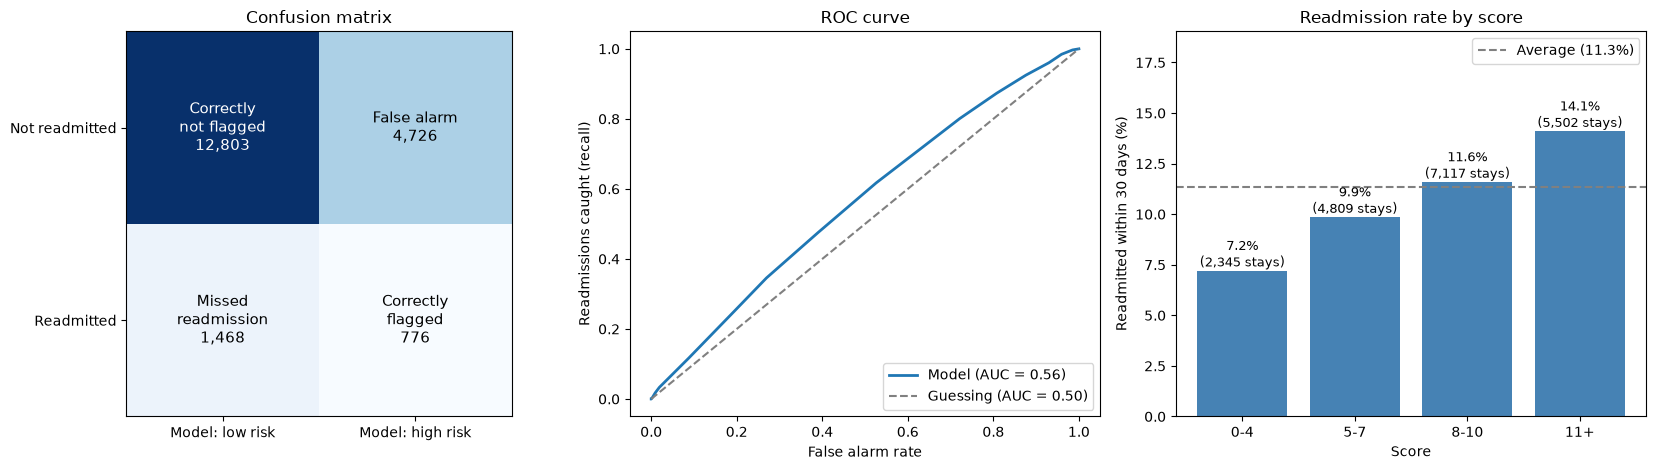

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Chart 1: confusion matrix
ax = axes[0]
cm = np.array([[tn, fp], [fn, tp]])
ax.imshow(cm, cmap="Blues")
names = [["Correctly\nnot flagged", "False alarm"], ["Missed\nreadmission", "Correctly\nflagged"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{names[i][j]}\n{cm[i, j]:,}", ha="center", va="center", fontsize=11,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Model: low risk", "Model: high risk"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Not readmitted", "Readmitted"])
ax.set_title("Confusion matrix")

# Chart 2: ROC curve
ax = axes[1]
f, t, _ = roc_curve(yte, risk_te)
ax.plot(f, t, linewidth=2, label=f"Model (AUC = {metrics['AUC-ROC']:.2f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Guessing (AUC = 0.50)")
ax.set_xlabel("False alarm rate"); ax.set_ylabel("Readmissions caught (recall)")
ax.set_title("ROC curve"); ax.legend(loc="lower right")

# Chart 3: does a higher score really mean more readmissions?
ax = axes[2]
bands = pd.cut(score_te, bins=[-1, 4, 7, 10, 19], labels=["0-4", "5-7", "8-10", "11+"])
rate = pd.Series(yte).groupby(bands, observed=False).mean() * 100
count = pd.Series(yte).groupby(bands, observed=False).size()
bars = ax.bar(rate.index.astype(str), rate.fillna(0).values, color="steelblue")
for bar, n in zip(bars, count.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{bar.get_height():.1f}%\n({n:,} stays)",
            ha="center", va="bottom",fontsize=9)
ax.axhline(yte.mean() * 100, linestyle="--", color="gray", label=f"Average ({yte.mean():.1%})")
ax.set_ylim(0, max(rate.fillna(0).max() * 1.35, 1))
ax.set_xlabel("Score"); ax.set_ylabel("Readmitted within 30 days (%)")
ax.set_title("Readmission rate by score"); ax.legend()

plt.tight_layout()
plt.savefig("../results/model1_charts.png", dpi=150)
plt.show()

In [ ]:
#Explain the result for one patient

In [ ]:
def explain_patient(k):
    """Show how the score was worked out for test patient number k."""
    idx = Xte.index[k]
    parts = score_parts(Xte.loc[[idx]]).iloc[0]
    total = int(parts.sum())
    print("=" * 62)
    print(f" Patient {df.loc[idx, 'patient_nbr']}   (age {df.loc[idx, 'age']}, {df.loc[idx, 'gender']})")
    print("=" * 62)
    print(f" Length of stay: {Xte.loc[idx, 'length_of_stay']:.0f} days".ljust(48) + f"{parts['Length of stay']:>3} points")
    print(f" Emergency admission: {'Yes' if Xte.loc[idx, 'emergency_admission'] else 'No'}".ljust(48) + f"{parts['Emergency admission']:>3} points")
    print(f" Number of diagnoses: {Xte.loc[idx, 'number_of_diagnoses']:.0f}".ljust(48) + f"{parts['Number of diagnoses']:>3} points")
    print(f" Emergency visits last year: {Xte.loc[idx, 'emergency_visits_last_year']:.0f}".ljust(48) + f"{parts['Emergency visits last year']:>3} points")
    print(" " + "-" * 60)
    print(" TOTAL SCORE".ljust(48) + f"{total:>3} out of 19")
    print(f" Estimated chance of readmission: {risk_te[k]:.1%}   (average patient: {ytr.mean():.1%})")
    print(f" Result: {'HIGH RISK' if total >= CUTOFF else 'LOW RISK'}   (high risk means a score of {CUTOFF:.0f} or more)")
    print(f" What really happened: {'readmitted within 30 days' if yte[k] == 1 else 'not readmitted within 30 days'}")
    print("=" * 62)

# One high-scoring and one low-scoring test patient
explain_patient(int(np.argmax(score_te)))
explain_patient(int(np.argmin(score_te)))

 Patient 24123573   (age [60-70), Male)
 Length of stay: 14 days                          7 points
 Emergency admission: Yes                         3 points
 Number of diagnoses: 9                           5 points
 Emergency visits last year: 4                    4 points
 ------------------------------------------------------------
 TOTAL SCORE                                     19 out of 19
 Estimated chance of readmission: 22.4%   (average patient: 11.4%)
 Result: HIGH RISK   (high risk means a score of 11 or more)
 What really happened: not readmitted within 30 days
 Patient 101334321   (age [50-60), Female)
 Length of stay: 1 days                           1 points
 Emergency admission: No                          0 points
 Number of diagnoses: 4                           0 points
 Emergency visits last year: 0                    0 points
 ------------------------------------------------------------
 TOTAL SCORE                                      1 out of 19
 Estimated chanc